# ML 02 — Exploratory data analysis and target definition

## What this notebook answers
A credible EDA should establish dataset quality, show how the target and predictors vary, identify relationships worth testing, and document limitations before modelling. This notebook calculates all summaries from the ML_01 output and generates fresh plots inline. No saved metrics or precomputed model results are used.

**Unit:** one layout × one wind direction. **Target:** canopy-averaged wind speed in m/s. **Scope:** scalar wind prediction only.

In [17]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

_candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in _candidates if (p / "data" / "raw").exists() and (p / "Machine Learning Pipeline").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the project repository.")
DATA_PROCESSED = ROOT / "data" / "processed"
processed_path = DATA_PROCESSED / "layout_level_dataset.csv"
if not processed_path.exists():
    raise FileNotFoundError("Run ML_01 first to build the processed dataset from raw files.")
df = pd.read_csv(processed_path)
TARGET = "target_U_canopy_mean_m_s"
NUMERIC_FEATURES = ["plan_area_density", "height_mean_m", "height_std_m", "height_max_m", "height_min_m", "height_range_m", "height_skew", "frac_taller_than_mean", "building_count"]
CATEGORICAL_FEATURES = ["configuration", "horizontal_configuration", "density_class"]
print("Repository:", ROOT)
print(f"Rows × columns: {df.shape[0]} × {df.shape[1]}")
print("Target:", TARGET)
display(df.head())

Repository: /Users/suhaanigarg/Desktop/T006-urban-microclimate-modelling
Rows × columns: 224 × 19
Target: target_U_canopy_mean_m_s


,simulation_id,layout_id,family_id,target_U_canopy_mean_m_s,plan_area_density,plan_area_density_sq,height_mean_m,height_std_m,height_max_m,height_min_m,height_range_m,height_skew,frac_taller_than_mean,wind_direction_deg,configuration,configuration_metadata_label,horizontal_configuration,density_class,building_count
0,UA0625_d00,UA0625,A0625,5.224270,0.062500,0.003906,16.0,0.0,16.0,16.0,0.0,0.0,0.0,0.0,idealized-uniform,idealized-uniform,Aligned,sparse,15
1,UA0625_d45,UA0625,A0625,3.368765,0.062500,0.003906,16.0,0.0,16.0,16.0,0.0,0.0,0.0,45.0,idealized-uniform,idealized-uniform,Aligned,sparse,15
2,UA1111_d00,UA1111,A1111,3.868836,0.111111,0.012346,16.0,0.0,16.0,16.0,0.0,0.0,0.0,0.0,idealized-uniform,idealized-uniform,Aligned,sparse,15
3,UA1111_d45,UA1111,A1111,2.341092,0.111111,0.012346,16.0,0.0,16.0,16.0,0.0,0.0,0.0,45.0,idealized-uniform,idealized-uniform,Aligned,sparse,15
4,UA16_d00,UA16,A16,3.226373,0.160000,0.025600,16.0,0.0,16.0,16.0,0.0,0.0,0.0,0.0,idealized-uniform,idealized-uniform,Aligned,sparse,15


## 1. Data quality and structural audit

Before interpreting relationships, verify row uniqueness, target completeness, numeric missingness, categorical levels, expected direction coverage, and the number of independent layouts/families. This prevents descriptive plots from hiding join or duplication problems.

In [18]:
quality = pd.DataFrame({
    "check": ["rows", "columns", "unique simulation IDs", "unique layouts", "unique families", "duplicate simulation IDs", "missing target", "missing cells", "infinite numeric cells"],
    "value": [len(df), len(df.columns), df.simulation_id.nunique(), df.layout_id.nunique(), df.family_id.nunique(), df.simulation_id.duplicated().sum(), df[TARGET].isna().sum(), int(df.isna().sum().sum()), int(np.isinf(df.select_dtypes(include=np.number)).sum().sum())]
})
display(quality)
missing_table = df.isna().sum().rename("missing_count").to_frame()
missing_table["missing_percent"] = (100 * missing_table.missing_count / len(df)).round(2)
display(missing_table)
assert df.simulation_id.is_unique, "Simulation IDs should be unique after the raw-data join."
assert df[TARGET].notna().all(), "Target values must be present for supervised learning."
assert np.isfinite(df[TARGET]).all(), "Target must contain finite values."
print("Wind directions:", sorted(df.wind_direction_deg.dropna().unique().tolist()))
print("Rows per direction:")
display(df.groupby("wind_direction_deg").size().rename("case_count").to_frame())

,check,value
0,rows,224
1,columns,19
2,unique simulation IDs,224
3,unique layouts,112
4,unique families,16
5,duplicate simulation IDs,0
6,missing target,0
7,missing cells,0
8,infinite numeric cells,0


,missing_count,missing_percent
simulation_id,0,0.0
layout_id,0,0.0
family_id,0,0.0
target_U_canopy_mean_m_s,0,0.0
plan_area_density,0,0.0
plan_area_density_sq,0,0.0
height_mean_m,0,0.0
height_std_m,0,0.0
height_max_m,0,0.0
height_min_m,0,0.0


Wind directions: [0.0, 45.0]
Rows per direction:


,case_count
wind_direction_deg,
0.0,112
45.0,112


## 2. Numeric summaries and outlier screening

Mean and standard deviation summarize central tendency and spread; median and quartiles are more robust to skew and extreme values. The IQR rule below is a **screening flag**, not an automatic instruction to delete cases: unusual CFD outputs may be physically meaningful.

In [19]:
numeric_columns = [c for c in NUMERIC_FEATURES + ["wind_direction_deg", TARGET] if c in df.columns]
summary = df[numeric_columns].describe(percentiles=[.05, .25, .5, .75, .95]).T
summary["skewness"] = df[numeric_columns].skew(numeric_only=True)
display(summary.round(4))

outlier_rows = []
for col in numeric_columns:
    q1, q3 = df[col].quantile([.25, .75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flagged = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_rows.append({"feature": col, "q1": q1, "q3": q3, "iqr_lower_fence": lower, "iqr_upper_fence": upper, "flagged_rows": int(flagged)})
outlier_table = pd.DataFrame(outlier_rows)
display(outlier_table.round(4))
print("Outlier flags are diagnostic only; no rows are dropped in this notebook.")

,count,mean,std,min,5%,25%,50%,75%,95%,max,skewness
plan_area_density,224.0,0.3185,0.1950,0.0625,0.0625,0.1478,0.3006,0.4656,0.6400,0.6400,0.2487
height_mean_m,224.0,16.0000,0.0000,16.0000,16.0000,16.0000,16.0000,16.0000,16.0000,16.0000,NaN
height_std_m,224.0,3.6263,1.9810,0.0000,0.0000,2.8284,2.8722,5.6569,5.7735,5.7735,-0.4551
height_max_m,224.0,23.9286,5.7601,16.0000,16.0000,20.0000,24.0000,26.0000,37.0000,37.0000,0.7954
height_min_m,224.0,10.4383,3.3566,4.0000,4.0000,8.0000,10.5909,12.5000,16.0000,16.0000,-0.0569
height_range_m,224.0,13.4903,7.9149,0.0000,0.0000,9.0000,13.0000,20.0000,28.0000,28.0000,-0.0570
height_skew,224.0,0.6201,1.0997,-0.3536,-0.3536,0.0000,0.0000,2.2361,2.4495,2.4495,0.9243
frac_taller_than_mean,224.0,0.1825,0.1483,0.0000,0.0000,0.0556,0.1667,0.3889,0.4000,0.4000,0.4165
building_count,224.0,16.5000,1.5034,15.0000,15.0000,15.0000,16.5000,18.0000,18.0000,18.0000,-0.0000
wind_direction_deg,224.0,22.5000,22.5504,0.0000,0.0000,0.0000,22.5000,45.0000,45.0000,45.0000,0.0000


,feature,q1,q3,iqr_lower_fence,iqr_upper_fence,flagged_rows
0,plan_area_density,0.1478,0.4656,-0.3289,0.9422,0
1,height_mean_m,16.0000,16.0000,16.0000,16.0000,0
2,height_std_m,2.8284,5.6569,-1.4142,9.8995,0
3,height_max_m,20.0000,26.0000,11.0000,35.0000,16
4,height_min_m,8.0000,12.5000,1.2500,19.2500,0
5,height_range_m,9.0000,20.0000,-7.5000,36.5000,0
6,height_skew,0.0000,2.2361,-3.3541,5.5902,0
7,frac_taller_than_mean,0.0556,0.3889,-0.4444,0.8889,0
8,building_count,15.0000,18.0000,10.5000,22.5000,0
9,wind_direction_deg,0.0000,45.0000,-67.5000,112.5000,0


Outlier flags are diagnostic only; no rows are dropped in this notebook.


## 3. Categorical and grouped distributions

Group summaries reveal whether the sample is balanced across wind direction, configuration, density class and plan family. These tables also show why random row-wise splitting is risky: related cases share layout and family structure.

In [20]:
for col in ["configuration", "horizontal_configuration", "density_class", "wind_direction_deg"]:
    print(f"\nCounts for {col}")
    display(df[col].value_counts(dropna=False).sort_index().rename("count").to_frame())

family_summary = df.groupby("family_id").agg(
    cases=(TARGET, "size"), layouts=("layout_id", "nunique"),
    target_mean=(TARGET, "mean"), target_std=(TARGET, "std"),
    target_min=(TARGET, "min"), target_max=(TARGET, "max")
).sort_values("target_mean")
display(family_summary.round(3))

group_summaries = {}
for col in ["wind_direction_deg", "configuration", "horizontal_configuration", "density_class"]:
    group_summaries[col] = df.groupby(col, dropna=False)[TARGET].agg(["count", "mean", "median", "std", "min", "max"]).round(3)
    print(f"\nTarget summary by {col}")
    display(group_summaries[col])


Counts for configuration


,count
configuration,
idealized-CL,64
idealized-HR,64
idealized-SM,64
idealized-uniform,32



Counts for horizontal_configuration


,count
horizontal_configuration,
Aligned,112
Staggered,112



Counts for density_class


...

,count,mean,median,std,min,max
configuration,,,,,,
idealized-CL,64,2.055,1.604,0.980,1.034,5.154
idealized-HR,64,2.014,1.546,1.004,0.966,5.144
idealized-SM,64,2.027,1.579,0.983,1.029,5.151
idealized-uniform,32,2.155,1.922,1.081,0.899,5.224



Target summary by horizontal_configuration


,count,mean,median,std,min,max
horizontal_configuration,,,,,,
Aligned,112,2.238,1.851,1.033,1.104,5.224
Staggered,112,1.861,1.439,0.926,0.899,4.287



Target summary by density_class


,count,mean,median,std,min,max
density_class,,,,,,
dense,84,1.366,1.355,0.313,0.899,2.748
medium,56,1.595,1.472,0.355,1.150,2.750
sparse,84,3.036,2.829,0.944,1.824,5.224


## 4. Plot A — Target distribution

The histogram shows the shape and range of the target. The boxplot complements it by making median, spread and potential extremes easier to see. Neither plot alone establishes model difficulty; the relationship between target and available predictors must also be examined.

/var/folders/f_/zqxtpml925n3kgjl49j4jb7m0000gn/T/ipykernel_84536/1769846494.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(df[TARGET].dropna(), vert=True)


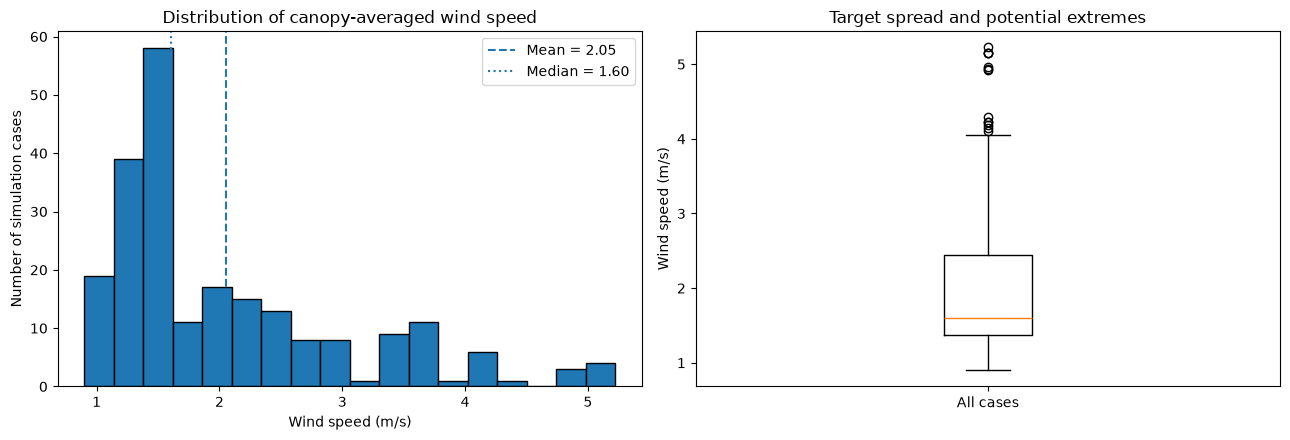

Target spans 0.899–5.224 m/s; mean=2.050, median=1.603, SD=0.997.
If mean and median differ noticeably, the target may be skewed; MAE and RMSE together help describe typical and larger errors.


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(df[TARGET], bins=18, edgecolor="black")
axes[0].axvline(df[TARGET].mean(), linestyle="--", label=f"Mean = {df[TARGET].mean():.2f}")
axes[0].axvline(df[TARGET].median(), linestyle=":", label=f"Median = {df[TARGET].median():.2f}")
axes[0].set(title="Distribution of canopy-averaged wind speed", xlabel="Wind speed (m/s)", ylabel="Number of simulation cases")
axes[0].legend()
axes[1].boxplot(df[TARGET].dropna(), vert=True)
axes[1].set(title="Target spread and potential extremes", ylabel="Wind speed (m/s)", xticks=[1], xticklabels=["All cases"])
plt.tight_layout(); plt.show()
print(f"Target spans {df[TARGET].min():.3f}–{df[TARGET].max():.3f} m/s; mean={df[TARGET].mean():.3f}, median={df[TARGET].median():.3f}, SD={df[TARGET].std():.3f}.")
print("If mean and median differ noticeably, the target may be skewed; MAE and RMSE together help describe typical and larger errors.")

## 5. Plot B — Predictor distributions

These histograms show whether geometric descriptors are constant, skewed or concentrated in a narrow range. A narrow range limits what the model can learn and how safely it can extrapolate.

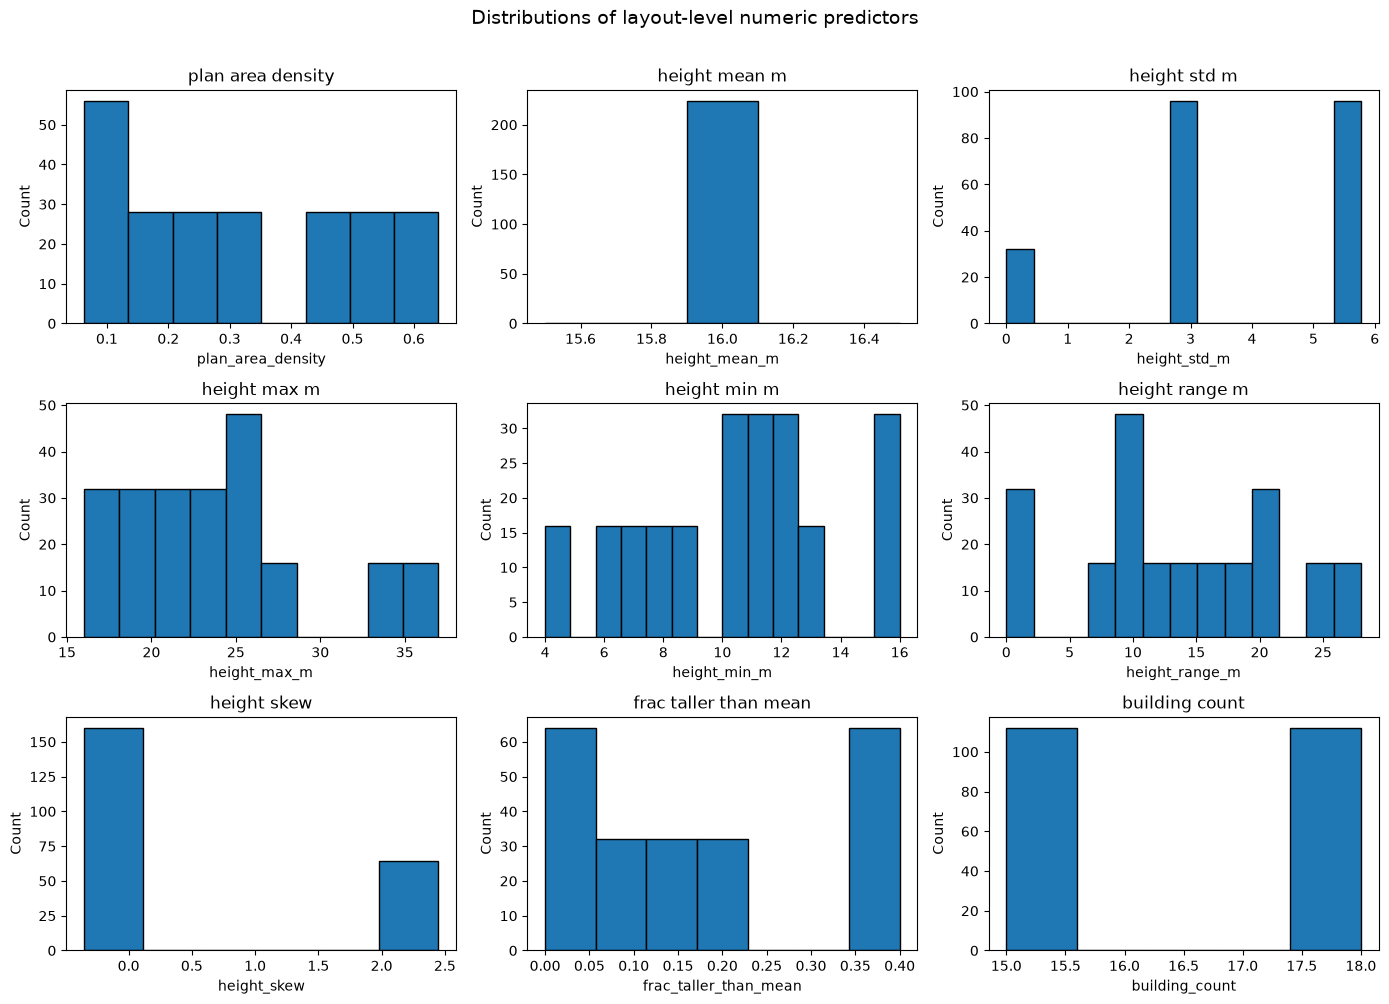

In [22]:
plot_features = [c for c in NUMERIC_FEATURES if c in df.columns]
cols = 3
rows = int(np.ceil(len(plot_features) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(14, 3.3 * rows))
axes = np.array(axes).reshape(-1)
for ax, col in zip(axes, plot_features):
    ax.hist(df[col].dropna(), bins=min(18, max(5, df[col].nunique())), edgecolor="black")
    ax.set_title(col.replace("_", " "))
    ax.set_xlabel(col); ax.set_ylabel("Count")
for ax in axes[len(plot_features):]: ax.set_visible(False)
fig.suptitle("Distributions of layout-level numeric predictors", y=1.01, fontsize=14)
plt.tight_layout(); plt.show()

## 6. Plot C — Target versus geometry

Scatterplots help identify trends, nonlinear relationships, clusters and heteroscedasticity. The dashed visual fit is not a causal relationship and is not used as a predictive model.

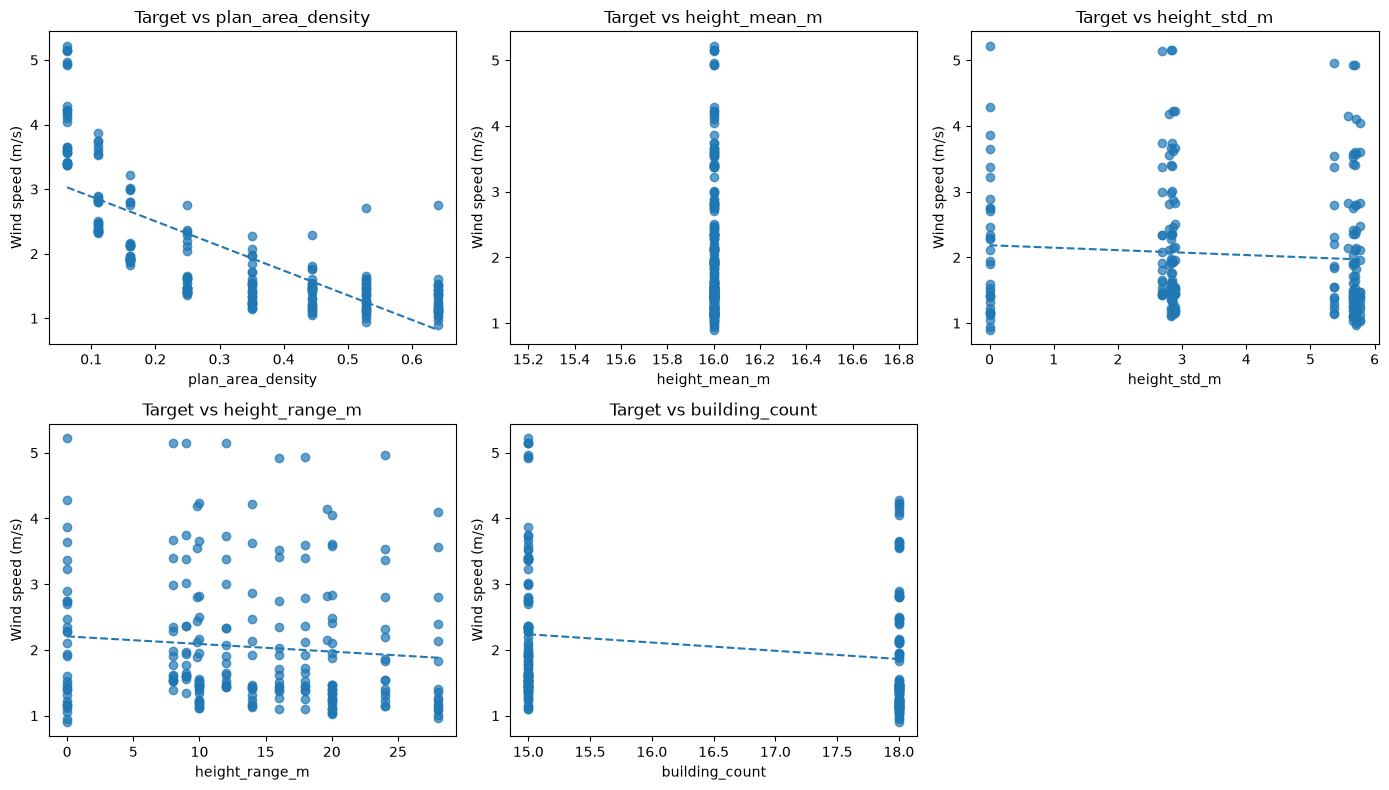

Pearson correlations with target (linear association only; not causal):


,pearson_r
plan_area_density,-0.747
building_count,-0.190
height_range_m,-0.092
height_std_m,-0.074
height_mean_m,NaN


In [23]:
scatter_features = [c for c in ["plan_area_density", "height_mean_m", "height_std_m", "height_range_m", "building_count"] if c in df.columns]
cols = 3; rows = int(np.ceil(len(scatter_features) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(14, 4 * rows))
axes = np.array(axes).reshape(-1)
for ax, col in zip(axes, scatter_features):
    ax.scatter(df[col], df[TARGET], alpha=.7)
    if df[col].nunique() > 1:
        z = np.polyfit(df[col].astype(float), df[TARGET].astype(float), 1)
        xline = np.linspace(df[col].min(), df[col].max(), 100)
        ax.plot(xline, np.polyval(z, xline), linestyle="--")
    ax.set(title=f"Target vs {col}", xlabel=col, ylabel="Wind speed (m/s)")
for ax in axes[len(scatter_features):]: ax.set_visible(False)
plt.tight_layout(); plt.show()
correlations = df[scatter_features + [TARGET]].corr(numeric_only=True)[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
print("Pearson correlations with target (linear association only; not causal):")
display(correlations.rename("pearson_r").to_frame().round(3))

## 7. Plot D — Wind direction and categorical comparisons

The target may depend on the angle between wind and street/layout orientation. The dataset only includes 0° and 45° in this subset, so any direction effect is conditional on those two sampled directions. Group boxplots reveal overlap and spread rather than only comparing means.

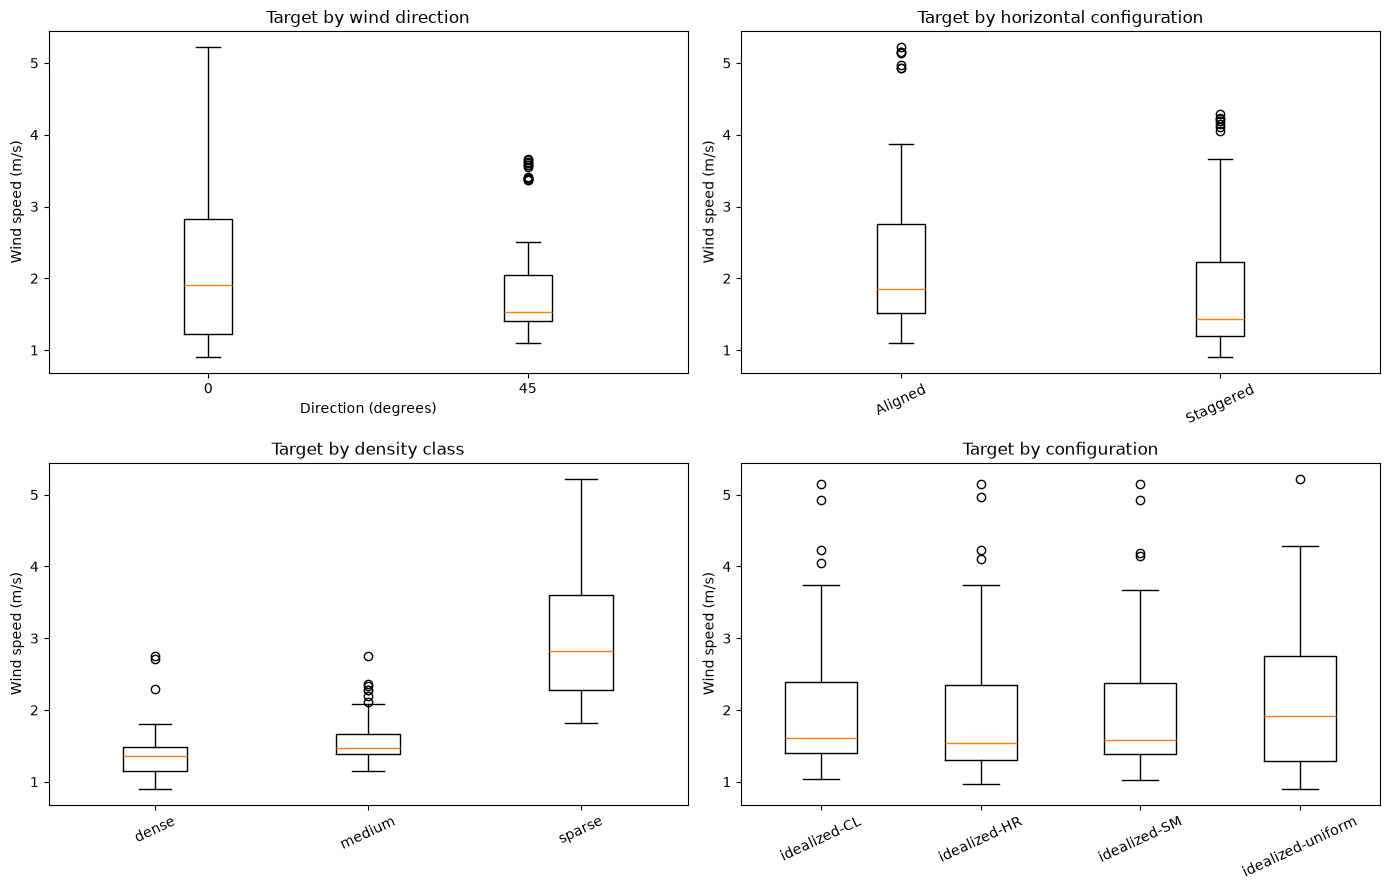

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
directions = sorted(df.wind_direction_deg.dropna().unique())
axes[0, 0].boxplot(
    [df.loc[df.wind_direction_deg == d, TARGET] for d in directions],
    tick_labels=[str(int(d)) for d in directions]
)
axes[0, 0].set(title="Target by wind direction", xlabel="Direction (degrees)", ylabel="Wind speed (m/s)")
for ax, col in zip(axes.flat[1:], ["horizontal_configuration", "density_class", "configuration"]):
    levels = sorted(df[col].dropna().unique())
    values = [df.loc[df[col] == level, TARGET].dropna() for level in levels]
    ax.boxplot(values, tick_labels=levels)
    ax.set(title=f"Target by {col.replace('_', ' ')}", ylabel="Wind speed (m/s)")
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

## 8. Plot E — Paired wind-direction response within layouts

Each layout has repeated simulations at two wind directions. Connecting the two observations for the same layout visualizes within-layout changes and reinforces that the two rows are related. The connecting line is descriptive, not a time trajectory.

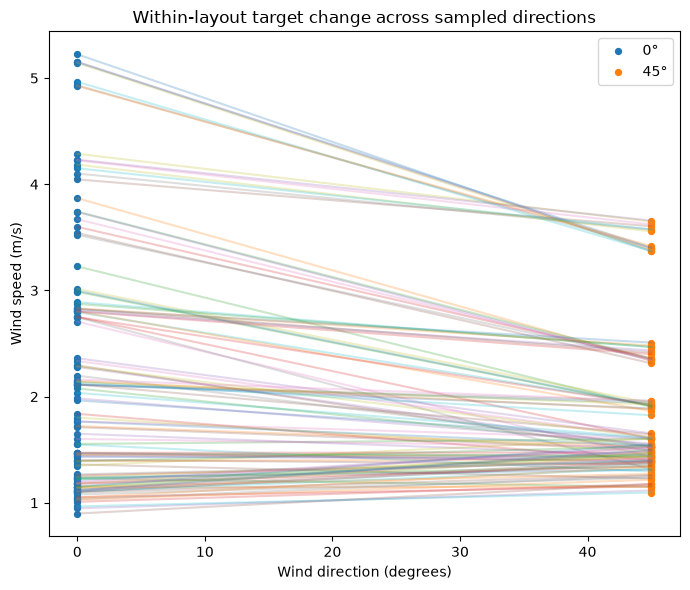

For 112 paired layouts, mean (45° − 0°) change = -0.375 m/s; median change = -0.220 m/s.


In [25]:
layout_direction = df.pivot_table(index="layout_id", columns="wind_direction_deg", values=TARGET, aggfunc="mean")
if len(directions := sorted(df.wind_direction_deg.dropna().unique())) >= 2 and all(d in layout_direction.columns for d in directions[:2]):
    d0, d1 = directions[:2]
    paired_layouts = layout_direction[[d0, d1]].dropna()
    fig, ax = plt.subplots(figsize=(7, 6))
    for _, row in paired_layouts.iterrows(): ax.plot([d0, d1], [row[d0], row[d1]], alpha=.25)
    ax.scatter([d0] * len(paired_layouts), paired_layouts[d0], s=18, label=f"{int(d0)}°")
    ax.scatter([d1] * len(paired_layouts), paired_layouts[d1], s=18, label=f"{int(d1)}°")
    ax.set(title="Within-layout target change across sampled directions", xlabel="Wind direction (degrees)", ylabel="Wind speed (m/s)")
    ax.legend(); plt.tight_layout(); plt.show()
    delta = paired_layouts[d1] - paired_layouts[d0]
    print(f"For {len(paired_layouts)} paired layouts, mean ({int(d1)}° − {int(d0)}°) change = {delta.mean():.3f} m/s; median change = {delta.median():.3f} m/s.")
else:
    print("At least two wind directions with paired layout coverage are needed for this plot.")

## 9. Plot F — Correlation and family-level variation

Correlations can reveal redundant predictors and simple linear associations, but they miss nonlinear relationships and do not prove causation. Family-level means help show the amount of between-family variation that the validation split must challenge.

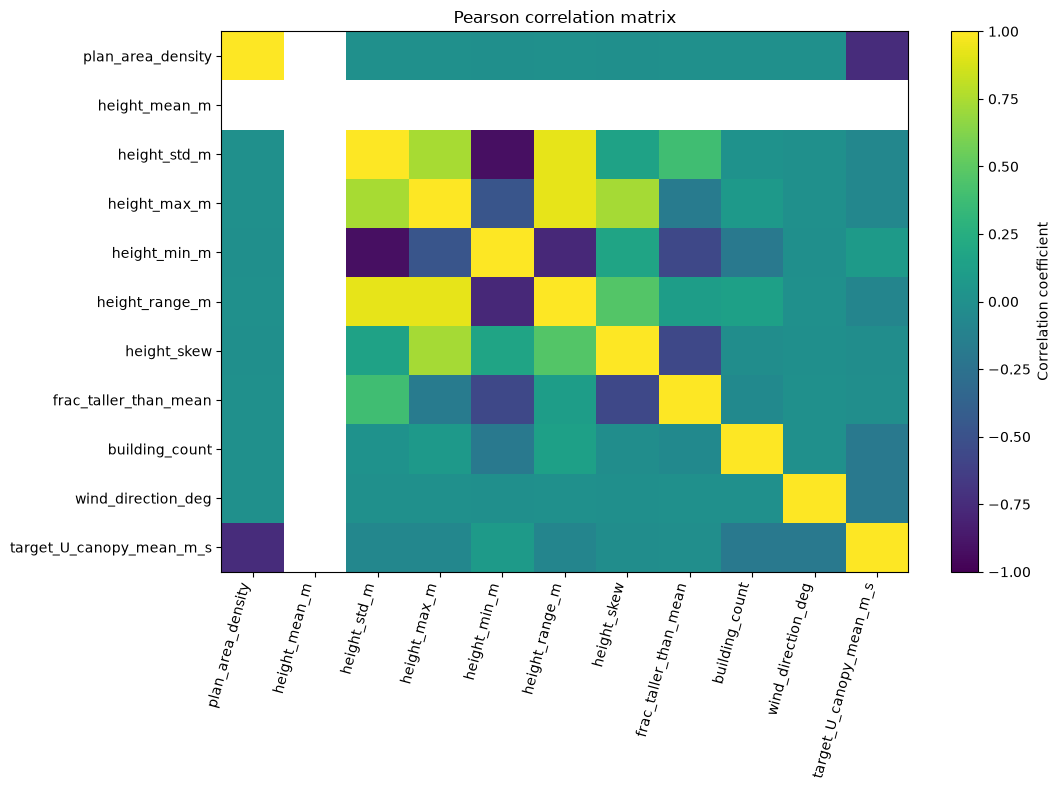

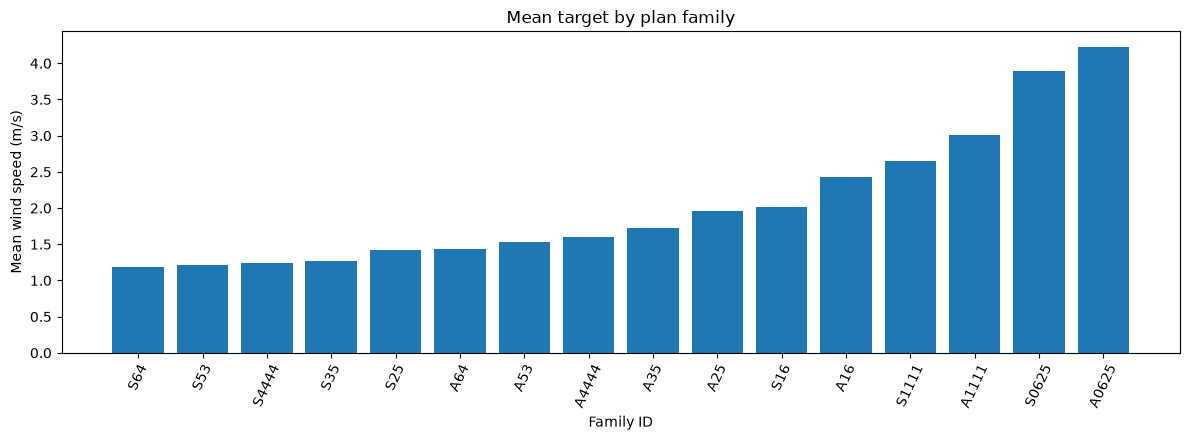

Family means span 1.184–4.230 m/s across 16 families.


In [26]:
corr_columns = [c for c in NUMERIC_FEATURES + ["wind_direction_deg", TARGET] if c in df.columns and pd.api.types.is_numeric_dtype(df[c])]
corr = df[corr_columns].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(11, 8))
im = ax.imshow(corr, vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=75, ha="right")
ax.set_yticks(range(len(corr.index)), corr.index)
ax.set_title("Pearson correlation matrix")
fig.colorbar(im, ax=ax, label="Correlation coefficient")
plt.tight_layout(); plt.show()

family_means = df.groupby("family_id")[TARGET].mean().sort_values()
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(family_means.index, family_means.values)
ax.set(title="Mean target by plan family", xlabel="Family ID", ylabel="Mean wind speed (m/s)")
ax.tick_params(axis="x", rotation=65)
plt.tight_layout(); plt.show()
print(f"Family means span {family_means.min():.3f}–{family_means.max():.3f} m/s across {len(family_means)} families.")

## 10. EDA findings and implications for modelling

The next cell writes a concise, data-dependent interpretation rather than a hard-coded claim. Use the tables and plots above to explain the actual patterns in the viva; do not claim a feature is important solely because it is correlated with the target.

In [27]:
target_skew = float(df[TARGET].skew())
max_corr = correlations.abs().max() if len(correlations) else np.nan
print("EDA takeaways")
print(f"1. The target is scalar canopy-averaged wind speed in m/s; observed range is {df[TARGET].min():.3f}–{df[TARGET].max():.3f}.")
print(f"2. Target skewness is {target_skew:.3f}; inspect the histogram before assuming a symmetric error distribution.")
print(f"3. The strongest absolute Pearson association among the inspected raw geometry features is {correlations.abs().idxmax() if len(correlations) else 'not available'} (|r|={max_corr:.3f}) if numeric relationships are defined.")
print(f"4. There are {df.layout_id.nunique()} layouts and {df.family_id.nunique()} families; related rows must be grouped during validation.")
print("5. The sampled directions are limited to the observed values listed above; generalization to arbitrary angles is not established.")
print("6. Layout summaries cannot represent local wake patterns or spatially resolved velocity/temperature fields. That is a stated limitation, not something EDA can fix.")
print("7. Do not delete IQR-flagged rows without a physical/data-quality reason. Keep the raw cases traceable.")

EDA takeaways
1. The target is scalar canopy-averaged wind speed in m/s; observed range is 0.899–5.224.
2. Target skewness is 1.345; inspect the histogram before assuming a symmetric error distribution.
3. The strongest absolute Pearson association among the inspected raw geometry features is plan_area_density (|r|=0.747) if numeric relationships are defined.
4. There are 112 layouts and 16 families; related rows must be grouped during validation.
5. The sampled directions are limited to the observed values listed above; generalization to arbitrary angles is not established.
6. Layout summaries cannot represent local wake patterns or spatially resolved velocity/temperature fields. That is a stated limitation, not something EDA can fix.
7. Do not delete IQR-flagged rows without a physical/data-quality reason. Keep the raw cases traceable.


## Target definition and limitations

- The target comes from the raw flow table's `U` column and is expressed in m/s.
- It is a **single canopy-averaged scalar** for each simulation, not a per-pixel velocity field.
- The profile ZIP is a sampled archive used for diagnostic cross-checking; it does not replace the official flow-table target.
- The dataset includes 224 idealized cases from 112 layouts and 16 families, with two sampled wind directions. Do not generalize beyond this experimental design without further data.
- EDA is descriptive. Predictive importance and generalization are assessed later with held-out grouped validation.